# Project 2
## Number of Orders Predictions

In [61]:
# Import the lib
import pandas as pd
import numpy as np

## Step 1: Import Dataset

In [62]:
#dataset importing 
dataset = pd.read_csv("supplement.csv")
dataset

,ID,Store_id,Store_Type,Location_Type,Region_Code,Date,Holiday,Discount,Orders
0,T1188341,171,S4,L2,R3,2019-06-01,0,No,162
1,T1188342,172,S1,L1,R1,2019-06-01,0,No,535
2,T1188343,173,S4,L2,R1,2019-06-01,0,No,408
3,T1188344,174,S1,L1,R4,2019-06-01,0,No,370
4,T1188345,170,S1,L1,R2,2019-06-01,0,No,206
...,...,...,...,...,...,...,...,...,...
22260,T1210601,186,S2,L5,R2,2019-07-31,0,No,80
22261,T1210602,11,S4,L2,R1,2019-07-31,0,No,128
22262,T1210603,185,S1,L1,R3,2019-07-31,0,Yes,481
22263,T1210604,69,S1,L1,R4,2019-07-31,0,No,329


## Step 2: Data Inspection and Data Handling

In [63]:
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22265 entries, 0 to 22264
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   ID             22265 non-null  object
 1   Store_id       22265 non-null  int64 
 2   Store_Type     22265 non-null  object
 3   Location_Type  22265 non-null  object
 4   Region_Code    22265 non-null  object
 5   Date           22265 non-null  object
 6   Holiday        22265 non-null  int64 
 7   Discount       22265 non-null  object
 8   Orders         22265 non-null  int64 
dtypes: int64(3), object(6)
memory usage: 1.5+ MB


In [64]:
dataset.isnull() # False
dataset.isnull().sum()

ID               0
Store_id         0
Store_Type       0
Location_Type    0
Region_Code      0
Date             0
Holiday          0
Discount         0
Orders           0
dtype: int64

In [11]:
dataset.describe() #mean median std descriptive statistics

,Store_id,Region_Code,Holiday
count,22265.000000,22265.000000,22265.000000
mean,183.000000,2.169863,0.032787
std,105.368395,1.046176,0.178082
min,1.000000,1.000000,0.000000
25%,92.000000,1.000000,0.000000
50%,183.000000,2.000000,0.000000
75%,274.000000,3.000000,0.000000
max,365.000000,4.000000,1.000000


## Step 3: Data Visualization

In [65]:
# import plotly 
!pip install plotly

In [66]:
import plotly.express as px

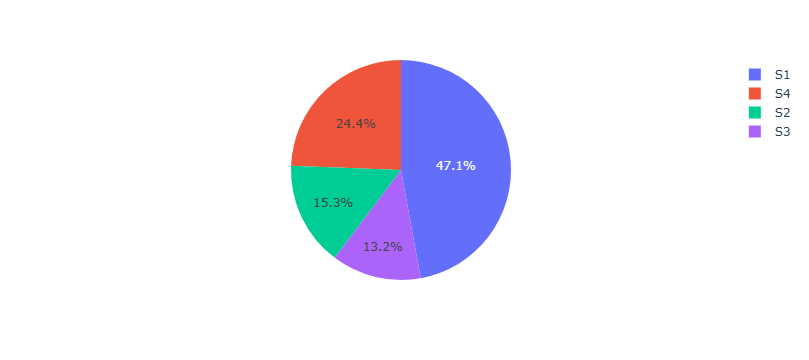

In [67]:
pie1 = dataset["Store_Type"].value_counts()
store = pie1.index
orders = pie1.values
fig = px.pie(dataset,values=orders,names=store)
fig.show()

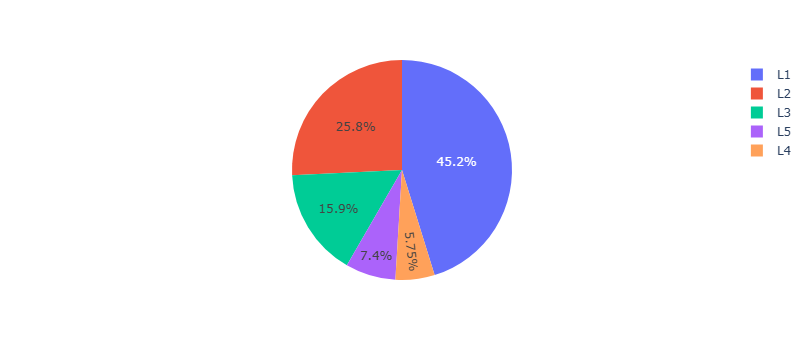

In [68]:
pie2 = dataset["Location_Type"].value_counts()
location = pie2.index
orders = pie2.values
fig = px.pie(dataset,values=orders,names=location)
fig.show()

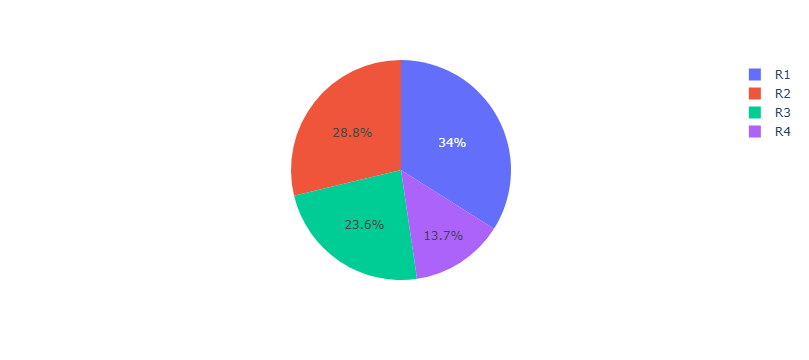

In [69]:
pie3 = dataset["Region_Code"].value_counts()
code = pie3.index
orders = pie3.values
fig = px.pie(dataset,values=orders,names=code)
fig.show()

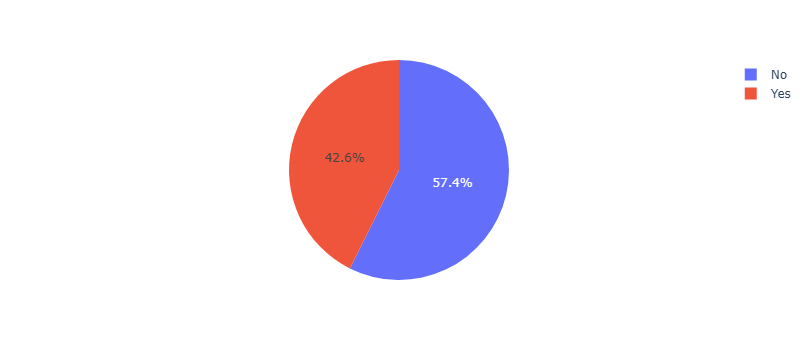

In [70]:
pie4 = dataset["Discount"].value_counts()
Discount = pie4.index
orders = pie4.values
fig = px.pie(dataset,values=orders,names=Discount)
fig.show()

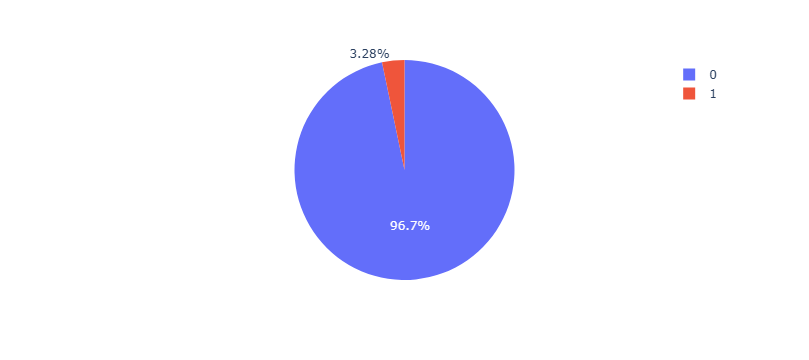

In [71]:
pie5 = dataset["Holiday"].value_counts()
Holiday = pie5.index
orders = pie5.values
fig = px.pie(dataset,values=orders,names=Holiday)
fig.show()

## Step 4: Data Preprocessing

In [72]:
# Handle NaN values first, then convert to string and apply mapping
dataset["Discount"] = dataset["Discount"].fillna("No").astype(str).str.strip().map({"No": 0, "Yes": 1})
dataset

,ID,Store_id,Store_Type,Location_Type,Region_Code,Date,Holiday,Discount,Orders
0,T1188341,171,S4,L2,R3,2019-06-01,0,0,162
1,T1188342,172,S1,L1,R1,2019-06-01,0,0,535
2,T1188343,173,S4,L2,R1,2019-06-01,0,0,408
3,T1188344,174,S1,L1,R4,2019-06-01,0,0,370
4,T1188345,170,S1,L1,R2,2019-06-01,0,0,206
...,...,...,...,...,...,...,...,...,...
22260,T1210601,186,S2,L5,R2,2019-07-31,0,0,80
22261,T1210602,11,S4,L2,R1,2019-07-31,0,0,128
22262,T1210603,185,S1,L1,R3,2019-07-31,0,1,481
22263,T1210604,69,S1,L1,R4,2019-07-31,0,0,329


In [73]:
# Handle NaN values first, then convert to string and apply mapping
dataset["Store_Type"] = dataset["Store_Type"].map({"S1" : 1,"S2" : 2, "S3" : 3, "S4" : 4})
dataset

,ID,Store_id,Store_Type,Location_Type,Region_Code,Date,Holiday,Discount,Orders
0,T1188341,171,4,L2,R3,2019-06-01,0,0,162
1,T1188342,172,1,L1,R1,2019-06-01,0,0,535
2,T1188343,173,4,L2,R1,2019-06-01,0,0,408
3,T1188344,174,1,L1,R4,2019-06-01,0,0,370
4,T1188345,170,1,L1,R2,2019-06-01,0,0,206
...,...,...,...,...,...,...,...,...,...
22260,T1210601,186,2,L5,R2,2019-07-31,0,0,80
22261,T1210602,11,4,L2,R1,2019-07-31,0,0,128
22262,T1210603,185,1,L1,R3,2019-07-31,0,1,481
22263,T1210604,69,1,L1,R4,2019-07-31,0,0,329


In [74]:
# Handle NaN values first, then convert to string and apply mapping
dataset["Location_Type"] = dataset["Location_Type"].map({"L1" : 1,"L2" : 2, "L3" : 3, "L4" : 4, "L5" : 5})
dataset

,ID,Store_id,Store_Type,Location_Type,Region_Code,Date,Holiday,Discount,Orders
0,T1188341,171,4,2,R3,2019-06-01,0,0,162
1,T1188342,172,1,1,R1,2019-06-01,0,0,535
2,T1188343,173,4,2,R1,2019-06-01,0,0,408
3,T1188344,174,1,1,R4,2019-06-01,0,0,370
4,T1188345,170,1,1,R2,2019-06-01,0,0,206
...,...,...,...,...,...,...,...,...,...
22260,T1210601,186,2,5,R2,2019-07-31,0,0,80
22261,T1210602,11,4,2,R1,2019-07-31,0,0,128
22262,T1210603,185,1,1,R3,2019-07-31,0,1,481
22263,T1210604,69,1,1,R4,2019-07-31,0,0,329


In [75]:
dataset["Region_Code"] = dataset["Region_Code"].map({"R1" : 1,"R2" : 2, "R3" : 3, "R4" : 4, "R5" : 5})
dataset

,ID,Store_id,Store_Type,Location_Type,Region_Code,Date,Holiday,Discount,Orders
0,T1188341,171,4,2,3,2019-06-01,0,0,162
1,T1188342,172,1,1,1,2019-06-01,0,0,535
2,T1188343,173,4,2,1,2019-06-01,0,0,408
3,T1188344,174,1,1,4,2019-06-01,0,0,370
4,T1188345,170,1,1,2,2019-06-01,0,0,206
...,...,...,...,...,...,...,...,...,...
22260,T1210601,186,2,5,2,2019-07-31,0,0,80
22261,T1210602,11,4,2,1,2019-07-31,0,0,128
22262,T1210603,185,1,1,3,2019-07-31,0,1,481
22263,T1210604,69,1,1,4,2019-07-31,0,0,329


In [76]:
# Fixed: Use square brackets [] instead of curly braces {} for DataFrame column selection
X = np.array(dataset[["Location_Type","Holiday","Discount","Region_Code"]])
# Fixed: Added missing square brackets [] for DataFrame column access
y = np.array(dataset["Orders"])

In [77]:
X

array([[2, 0, 0, 3],
       [1, 0, 0, 1],
       [2, 0, 0, 1],
       ...,
       [1, 0, 1, 3],
       [1, 0, 0, 4],
       [1, 0, 0, 2]])

In [78]:
y

array([162, 535, 408, ..., 481, 329, 290])

In [79]:
# Buliding the Machine Learning Model 
from sklearn.model_selection import train_test_split

In [80]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size = 0.2,random_state=42)

In [81]:
X_train

array([[1, 1, 0, 2],
       [2, 0, 0, 3],
       [3, 0, 1, 1],
       ...,
       [2, 0, 0, 2],
       [1, 0, 0, 2],
       [2, 0, 0, 1]])

In [82]:
len(X_train)

17812

In [83]:
y_train

array([470, 432, 172, ..., 317, 247, 402])

## Step 5: Buliding the ML Model

In [84]:
!pip install lightgbm

In [86]:
import lightgbm as ltb
model = ltb.LGBMRegressor()

In [87]:
model.fit(X_train,y_train)

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000933 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 15
[LightGBM] [Info] Number of data points in the train set: 17812, number of used features: 4
[LightGBM] [Info] Start training from score 333.266057


LGBMRegressor()

In [88]:
y_pred = model.predict(X_test)

In [89]:
y_pred

array([374.50628697, 391.08098721, 369.53772758, ..., 368.05616523,
       321.65313949, 354.28537073])

In [97]:
y_test

array([537, 558, 254, ..., 212, 141, 213])

In [98]:
data = pd.DataFrame(data={"Predicted Orders": y_pred.flatten()})
data

,Predicted Orders
0,374.506287
1,391.080987
2,369.537728
3,302.604638
4,302.604638
...,...
4448,312.081655
4449,379.734933
4450,368.056165
4451,321.653139
